# Forecasting Produksi Padi di Sumatera
## Pemodelan Machine Learning untuk Prediksi Produksi Padi

**Dataset:** Data Tanaman Padi Sumatera (BPS & BMKG, 1993–2020)  
**Tujuan:** Membandingkan performa 6 algoritma machine learning untuk forecasting produksi padi di Sumatera, kemudian menentukan model terbaik berdasarkan metrik evaluasi.

**Algoritma yang Digunakan:**
1. Decision Tree Regressor
2. K-Nearest Neighbors (KNN) Regressor
3. Multilayer Perceptron (MLP) Regressor
4. Random Forest Regressor
5. XGBoost Regressor
6. LightGBM Regressor

**Metrik Evaluasi:** MAE, RMSE, R², Pearson Correlation Coefficient

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Tahap 1: Persiapan Lingkungan & Import Library

In [ ]:
# ============================================================
# 1.1 Instalasi Library
# ============================================================

!pip install xgboost lightgbm

In [ ]:
# ============================================================
# 1.2 Import Seluruh Library yang Dibutuhkan
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

# # Style untuk visualisasi
# plt.style.use('seaborn-v0_8-whitegrid')
# plt.rcParams['figure.figsize'] = (12, 6)
# plt.rcParams['font.size'] = 11
# plt.rcParams['axes.titlesize'] = 14
# plt.rcParams['axes.labelsize'] = 12

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Seluruh library berhasil diimpor.')

Seluruh library berhasil diimpor.


---
## Tahap 2: Load Dataset & Exploratory Data Analysis (EDA)

In [ ]:
# ============================================================
# 2.1 Load Dataset
# ============================================================

df = pd.read_csv('/content/drive/MyDrive/Datasets/Data_Tanaman_Padi_Sumatera_version_1.csv')

print(f'\nDimensi Dataset: {df.shape[0]} baris × {df.shape[1]} kolom')
print(f'Kolom: {list(df.columns)}')


Dimensi Dataset: 224 baris × 7 kolom
Kolom: ['Provinsi', 'Tahun', 'Produksi', 'Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata']


In [ ]:
# ============================================================
# 2.2 Menampilkan 5 Data Teratas dan Terbawah
# ============================================================

print('='*70)
print('5 DATA TERATAS')
print('='*70)
display(df.head())

print('\n' + '='*70)
print('5 DATA TERBAWAH')
print('='*70)
display(df.tail())

5 DATA TERATAS


,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,Aceh,1993,1329536.0,323589.0,1627.0,82.00,26.06
1,Aceh,1994,1299699.0,329041.0,1521.0,82.12,26.92
2,Aceh,1995,1382905.0,339253.0,1476.0,82.72,26.27
3,Aceh,1996,1419128.0,348223.0,1557.0,83.00,26.08
4,Aceh,1997,1368074.0,337561.0,1339.0,82.46,26.31



5 DATA TERBAWAH


,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
219,Lampung,2016,3831923.00,390799.00,2317.6,79.40,26.45
220,Lampung,2017,4090654.00,396559.00,1825.1,77.04,26.36
221,Lampung,2018,2488641.91,511940.93,1385.8,76.05,25.50
222,Lampung,2019,2164089.33,464103.42,1706.4,78.03,27.23
223,Lampung,2020,2604913.29,545149.05,2211.3,75.80,24.58


In [ ]:
# ============================================================
# 2.3 Struktur Data dan Tipe Data
# ============================================================

print('='*70)
print('INFORMASI STRUKTUR DATASET')
print('='*70)
df.info()

print('\n' + '='*70)
print('JUMLAH UNIK PER KOLOM')
print('='*70)
print(df.nunique())

INFORMASI STRUKTUR DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Provinsi        224 non-null    object 
 1   Tahun           224 non-null    int64  
 2   Produksi        224 non-null    float64
 3   Luas Panen      224 non-null    float64
 4   Curah hujan     224 non-null    float64
 5   Kelembapan      224 non-null    float64
 6   Suhu rata-rata  224 non-null    float64
dtypes: float64(5), int64(1), object(1)
memory usage: 12.4+ KB

JUMLAH UNIK PER KOLOM
Provinsi            8
Tahun              28
Produksi          224
Luas Panen        224
Curah hujan       220
Kelembapan        180
Suhu rata-rata    136
dtype: int64


In [ ]:
# ============================================================
# 2.4 Pengecekan Missing Values
# ============================================================

missing = df.isnull().sum()
print('='*70)
print('PENGECEKAN MISSING VALUES')
print('='*70)
print(missing)
print(f'\n Total missing values: {missing.sum()}')

PENGECEKAN MISSING VALUES
Provinsi          0
Tahun             0
Produksi          0
Luas Panen        0
Curah hujan       0
Kelembapan        0
Suhu rata-rata    0
dtype: int64

 Total missing values: 0


In [ ]:
# ============================================================
# 2.5 Statistik Deskriptif
# ============================================================

print('='*70)
print('STATISTIK DESKRIPTIF')
print('='*70)
display(df.describe().round(2))

STATISTIK DESKRIPTIF


,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
count,224.00,224.00,224.00,224.00,224.00,224.00
mean,2006.50,1679700.89,374349.97,2452.49,80.95,26.80
std,8.10,1161387.39,232751.16,1031.97,4.88,1.20
min,1993.00,42938.00,63142.04,222.50,54.20,22.19
25%,1999.75,548857.00,146919.50,1703.52,78.97,26.18
50%,2006.50,1667773.00,373551.50,2315.70,82.38,26.73
75%,2013.25,2436850.75,514570.25,3039.70,84.00,27.20
max,2020.00,4881089.00,872737.00,5522.00,90.60,29.85


In [ ]:
# ============================================================
# 2.6 Daftar Provinsi dalam Dataset
# ============================================================

print('='*70)
print('DAFTAR PROVINSI DI SUMATERA')
print('='*70)
provinsi_list = df['Provinsi'].unique()
for i, prov in enumerate(provinsi_list, 1):
    count = len(df[df['Provinsi'] == prov])
    print(f'  {i}. {prov} ({count} data)')
print(f'\n Total: {len(provinsi_list)} provinsi, {len(df)} data keseluruhan')

DAFTAR PROVINSI DI SUMATERA
  1. Aceh (28 data)
  2. Sumatera Utara (28 data)
  3. Sumatera Barat (28 data)
  4. Riau (28 data)
  5. Jambi (28 data)
  6. Sumatera Selatan (28 data)
  7. Bengkulu (28 data)
  8. Lampung (28 data)

 Total: 8 provinsi, 224 data keseluruhan


### Visualisasi Eksplorasi Data

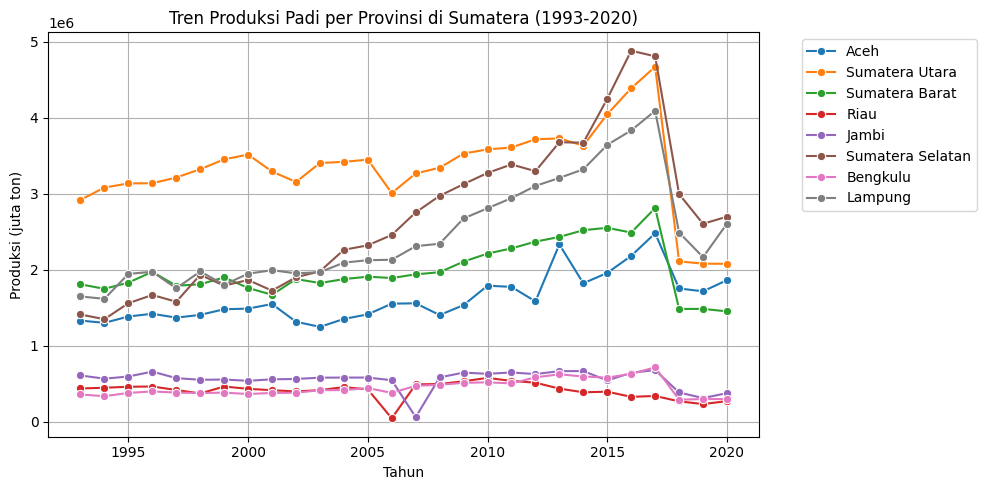

In [ ]:
# ============================================================
# 2.7 Grafik Tren Produksi Padi per Provinsi (1993-2020)
# ============================================================

plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="Tahun", y="Produksi", hue="Provinsi", marker="o")

plt.title("Tren Produksi Padi per Provinsi di Sumatera (1993-2020)")
plt.xlabel("Tahun")
plt.ylabel("Produksi (juta ton)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

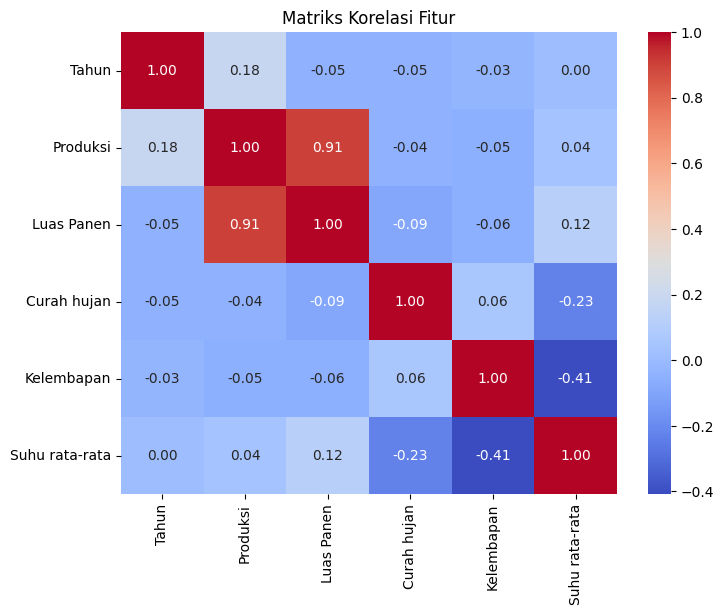

Korelasi terhadap Produksi:
Luas Panen        0.905622
Tahun             0.182527
Suhu rata-rata    0.041160
Curah hujan      -0.042129
Kelembapan       -0.052316
Name: Produksi, dtype: float64


In [ ]:
# ============================================================
# 2.8 Heatmap Matriks Korelasi
# ============================================================

# Hitung korelasi kolom numerik
corr_matrix = df.corr(numeric_only=True)

# Heatmap sederhana
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriks Korelasi Fitur")
plt.show()

# Korelasi dengan target produksi
print('='*70)
print("Korelasi terhadap Produksi:")
print('='*70)
corr_target = (
    corr_matrix["Produksi"].drop("Produksi").sort_values(ascending=False)
)
print(corr_target)

---
## Tahap 3: Data Preprocessing

In [ ]:
# ============================================================
# 3.1 Encoding Variabel Kategorikal (Label Encoding)
# ============================================================

# Buat salinan dataframe agar data asli tidak berubah
df_encoded = df.copy()

# Inisialisasi dan terapkan Label Encoder
label_encoder = LabelEncoder()
df_encoded['Provinsi'] = label_encoder.fit_transform(df_encoded['Provinsi'])

# Tampilkan mapping encoding
print('='*70)
print('MAPPING LABEL ENCODING - PROVINSI')
print('='*70)
for i, label in enumerate(label_encoder.classes_):
    print(f'  {label:20s} → {i}')

display(df_encoded.head())

MAPPING LABEL ENCODING - PROVINSI
  Aceh                 → 0
  Bengkulu             → 1
  Jambi                → 2
  Lampung              → 3
  Riau                 → 4
  Sumatera Barat       → 5
  Sumatera Selatan     → 6
  Sumatera Utara       → 7


,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,0,1993,1329536.0,323589.0,1627.0,82.00,26.06
1,0,1994,1299699.0,329041.0,1521.0,82.12,26.92
2,0,1995,1382905.0,339253.0,1476.0,82.72,26.27
3,0,1996,1419128.0,348223.0,1557.0,83.00,26.08
4,0,1997,1368074.0,337561.0,1339.0,82.46,26.31


In [ ]:
# ============================================================
# 3.2 Pemisahan Fitur (X) dan Target (y)
# ============================================================

# Definisikan fitur dan target
feature_columns = ['Provinsi', 'Tahun', 'Luas Panen', 'Curah hujan',
                   'Kelembapan', 'Suhu rata-rata']
target_column = 'Produksi'

X = df_encoded[feature_columns]
y = df_encoded[target_column]

print(f'Dimensi Fitur (X): {X.shape}')
print(f'Dimensi Target (y): {y.shape}')
print(f'\nFitur yang digunakan: {feature_columns}')
print(f'Target: {target_column}')

Dimensi Fitur (X): (224, 6)
Dimensi Target (y): (224,)

Fitur yang digunakan: ['Provinsi', 'Tahun', 'Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata']
Target: Produksi


In [ ]:
# ============================================================
# 3.3 Pembagian Data: Training (80%) dan Testing (20%)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print('='*70)
print('PEMBAGIAN DATA TRAINING DAN TESTING')
print('='*70)
print(f'  Data Training : {X_train.shape[0]} sampel ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'  Data Testing  : {X_test.shape[0]} sampel ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'  Total Data    : {len(X)} sampel')

PEMBAGIAN DATA TRAINING DAN TESTING
  Data Training : 179 sampel (80%)
  Data Testing  : 45 sampel (20%)
  Total Data    : 224 sampel


In [ ]:
# ============================================================
# 3.4 Feature Scaling (StandardScaler)
# ============================================================

scaler = StandardScaler()

# Fit pada data training, transform keduanya
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Konversi ke DataFrame agar mudah dibaca
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_columns, index=X_test.index)

print('\nData scaled digunakan untuk: KNN, MLP')
print('Data asli digunakan untuk: Decision Tree, Random Forest, XGBoost, LightGBM')

print('\n' + '='*70)
print('SAMPLE DATA TRAINING (SETELAH SCALING)')
print('='*70)
display(X_train_scaled.head())


Data scaled digunakan untuk: KNN, MLP
Data asli digunakan untuk: Decision Tree, Random Forest, XGBoost, LightGBM

SAMPLE DATA TRAINING (SETELAH SCALING)


,Provinsi,Tahun,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
127,-0.647604,0.168963,-0.996532,-0.205309,0.529202,-0.288238
66,0.650020,-0.453350,0.129516,2.406284,-1.895009,1.944822
73,0.650020,0.417889,0.333245,2.697537,1.248858,-0.873684
96,0.217479,-0.204425,-1.032623,-0.431592,0.576494,-0.221330
119,-0.647604,-0.826738,-0.877735,-1.550902,0.765661,0.765566


---
## Tahap 4: Pelatihan Model (Model Training)
Pada tahap ini, kita melatih 6 algoritma machine learning untuk forecasting produksi padi:
1. Decision Tree Regressor
2. K-Nearest Neighbors (KNN) Regressor
3. Multilayer Perceptron (MLP) Regressor
4. Random Forest Regressor
5. XGBoost Regressor
6. LightGBM Regressor

In [ ]:
# ============================================================
# 4.1 Definisi dan Pelatihan Seluruh Model
# ============================================================
# Setiap model dilatih menggunakan data training yang sesuai:
# - Model berbasis pohon: menggunakan data ASLI (X_train)
# - Model berbasis jarak/gradient: menggunakan data SCALED
# ============================================================

# Definisi 6 model beserta konfigurasi
models = {
    'Decision Tree': {
        'model': DecisionTreeRegressor(random_state=RANDOM_STATE),
        'use_scaled': False,
        'description': 'Model pohon keputusan sederhana (baseline non-linear)'
    },
    'KNN': {
        'model': KNeighborsRegressor(n_neighbors=5),
        'use_scaled': True,
        'description': 'K-Nearest Neighbors Regressor (instance-based learning)'
    },
    'MLP': {
        'model': MLPRegressor(
            hidden_layer_sizes=(100, 50),
            max_iter=1000,
            random_state=RANDOM_STATE,
            early_stopping=True,
            validation_fraction=0.1
        ),
        'use_scaled': True,
        'description': 'Multilayer Perceptron / Neural Network'
    },
    'Random Forest': {
        'model': RandomForestRegressor(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        'use_scaled': False,
        'description': 'Ensemble Bagging (multi-pohon keputusan)'
    },
    'XGBoost': {
        'model': XGBRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            random_state=RANDOM_STATE,
            verbosity=0
        ),
        'use_scaled': False,
        'description': 'Extreme Gradient Boosting (sekuensial + regularisasi)'
    },
    'LightGBM': {
        'model': LGBMRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            num_leaves=31,
            random_state=RANDOM_STATE,
            verbose=-1
        ),
        'use_scaled': False,
        'description': 'Light Gradient Boosting Machine (leaf-wise)'
    }
}

# Pelatihan seluruh model
print('='*70)
print('PROSES PELATIHAN 6 MODEL MACHINE LEARNING')
print('='*70)

trained_models = {}

for name, config in models.items():
    print(f'\nMelatih {name}...')
    print(f'   Deskripsi : {config["description"]}')
    print(f'   Data      : {"Scaled" if config["use_scaled"] else "Original"}')

    # Pilih data training yang sesuai
    if config['use_scaled']:
        X_tr = X_train_scaled
    else:
        X_tr = X_train

    # Latih model
    config['model'].fit(X_tr, y_train)
    trained_models[name] = config

    print(f'   {name} berhasil dilatih')

print('\n' + '='*70)
print('SELURUH 6 MODEL BERHASIL DILATIH')
print('='*70)

PROSES PELATIHAN 6 MODEL MACHINE LEARNING

Melatih Decision Tree...
   Deskripsi : Model pohon keputusan sederhana (baseline non-linear)
   Data      : Original
   Decision Tree berhasil dilatih

Melatih KNN...
   Deskripsi : K-Nearest Neighbors Regressor (instance-based learning)
   Data      : Scaled
   KNN berhasil dilatih

Melatih MLP...
   Deskripsi : Multilayer Perceptron / Neural Network
   Data      : Scaled
   MLP berhasil dilatih

Melatih Random Forest...
   Deskripsi : Ensemble Bagging (multi-pohon keputusan)
   Data      : Original
   Random Forest berhasil dilatih

Melatih XGBoost...
   Deskripsi : Extreme Gradient Boosting (sekuensial + regularisasi)
   Data      : Original
   XGBoost berhasil dilatih

Melatih LightGBM...
   Deskripsi : Light Gradient Boosting Machine (leaf-wise)
   Data      : Original
   LightGBM berhasil dilatih

SELURUH 6 MODEL BERHASIL DILATIH


---
## Tahap 5: Prediksi & Visualisasi Hasil Prediksi

In [ ]:
# ============================================================
# 5.1 Melakukan Prediksi pada Data Testing
# ============================================================

predictions = {}

print('='*70)
print('PREDIKSI PRODUKSI PADI MENGGUNAKAN 6 MODEL')
print('='*70)

for name, config in trained_models.items():
    # Pilih data testing yang sesuai
    if config['use_scaled']:
        X_te = X_test_scaled
    else:
        X_te = X_test

    # Prediksi
    y_pred = config['model'].predict(X_te)
    predictions[name] = y_pred

    print(f'  {name:15s} → Prediksi selesai ({len(y_pred)} sampel)')

print(f'\nTotal data testing: {len(y_test)} sampel')

PREDIKSI PRODUKSI PADI MENGGUNAKAN 6 MODEL
  Decision Tree   → Prediksi selesai (45 sampel)
  KNN             → Prediksi selesai (45 sampel)
  MLP             → Prediksi selesai (45 sampel)
  Random Forest   → Prediksi selesai (45 sampel)
  XGBoost         → Prediksi selesai (45 sampel)
  LightGBM        → Prediksi selesai (45 sampel)

Total data testing: 45 sampel


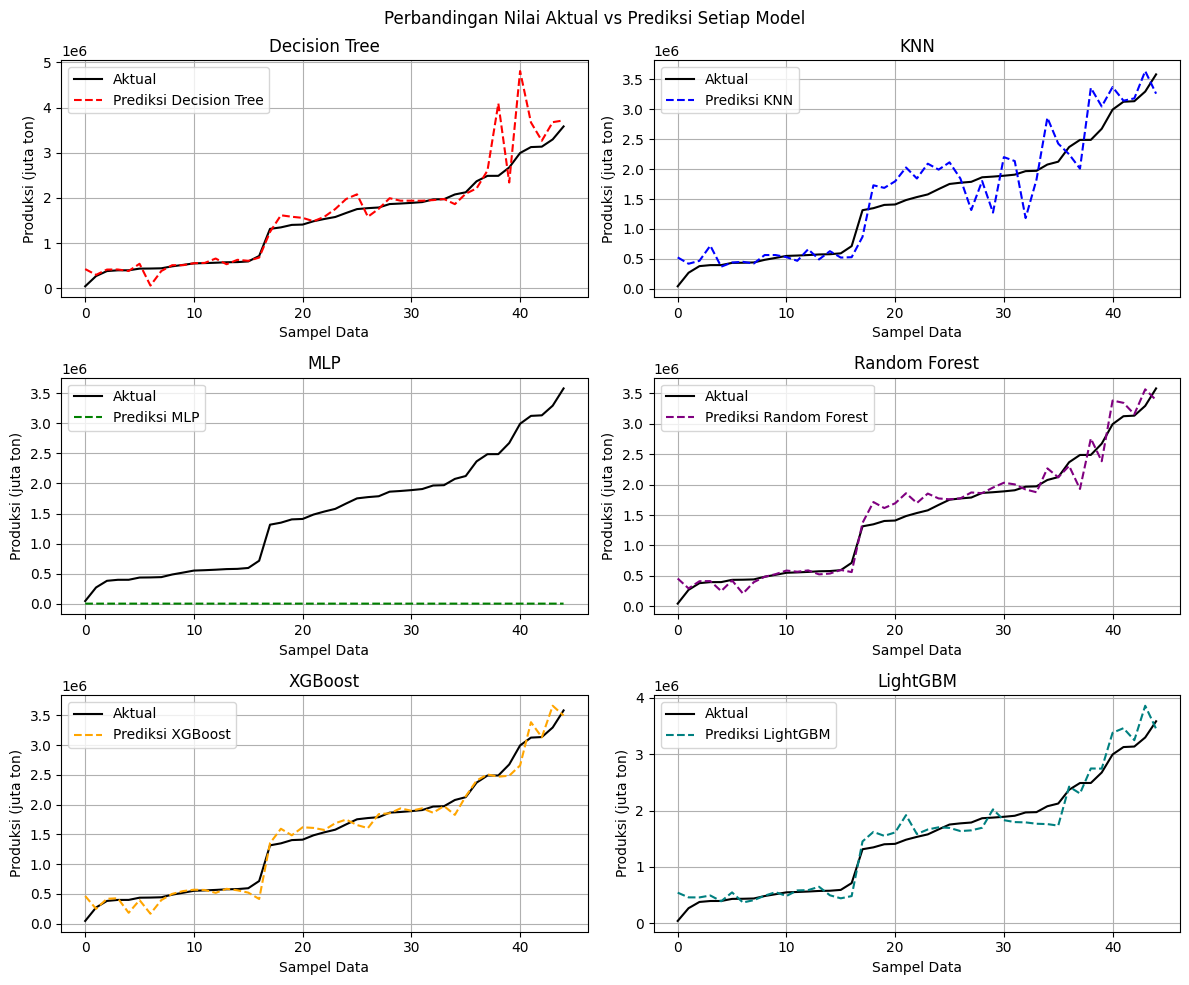

In [ ]:
# ============================================================
# 5.2 Visualisasi: Perbandingan Nilai Aktual vs Prediksi
#     (Line Plot)
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

# Warna standar matplotlib
colors_model = ['red', 'blue', 'green', 'purple', 'orange', 'teal']

for idx, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[idx]

    # Urutkan nilai agar grafik mudah dibaca
    sorted_idx = np.argsort(y_test.values)
    y_actual_sorted = y_test.values[sorted_idx]
    y_pred_sorted = y_pred[sorted_idx]

    ax.plot(y_actual_sorted, label='Aktual', color='black')
    ax.plot(y_pred_sorted, label=f'Prediksi {name}', color=colors_model[idx], linestyle='--')

    ax.set_title(name)
    ax.set_xlabel('Sampel Data')
    ax.set_ylabel('Produksi (juta ton)')
    ax.legend()
    ax.grid(True)

plt.suptitle('Perbandingan Nilai Aktual vs Prediksi Setiap Model')
plt.tight_layout()
plt.show()

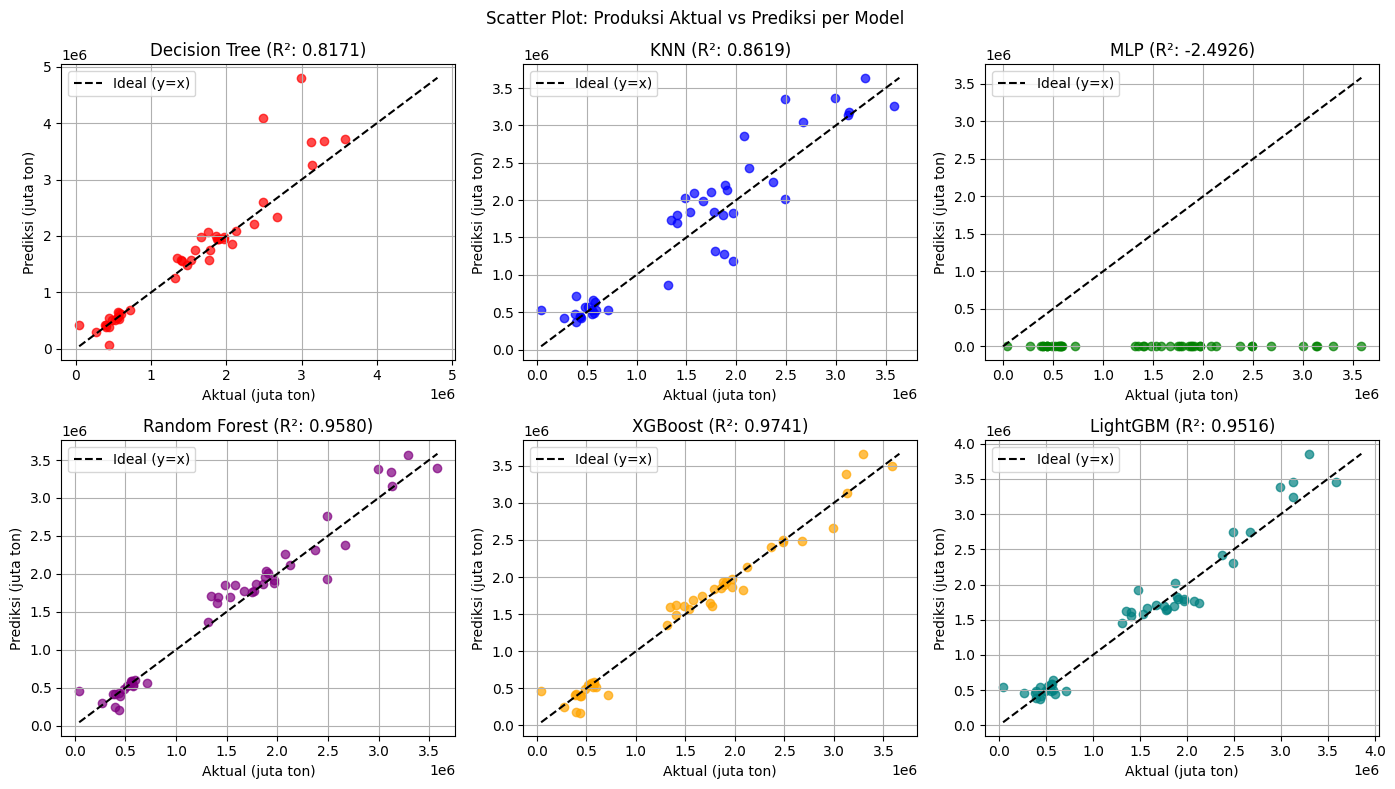

In [ ]:
# ============================================================
# 5.3 Visualisasi: Scatter Plot Aktual vs Prediksi
#     (dengan garis referensi ideal y = x)
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

colors_model = ['red', 'blue', 'green', 'purple', 'orange', 'teal']

for idx, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[idx]

    # Scatter plot data aktual vs prediksi
    ax.scatter(y_test, y_pred, color=colors_model[idx], alpha=0.7)

    # Garis diagonal ideal (y = x)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal (y=x)')

    # Menampilkan nilai R2 di judul plot agar lebih simpel
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f'{name} (R²: {r2:.4f})')

    ax.set_xlabel('Aktual (juta ton)')
    ax.set_ylabel('Prediksi (juta ton)')
    ax.legend()
    ax.grid(True)

plt.suptitle('Scatter Plot: Produksi Aktual vs Prediksi per Model')
plt.tight_layout()
plt.show()

---
## Tahap 6: Evaluasi Model & Perbandingan Performa
Pada tahap ini, performa seluruh model dievaluasi menggunakan **4 metrik**:
1. **MAE** (Mean Absolute Error) — Rata-rata kesalahan absolut
2. **RMSE** (Root Mean Squared Error) — Akar rata-rata kesalahan kuadrat
3. **R²** (Koefisien Determinasi) — Proporsi variansi yang dapat dijelaskan model
4. **Pearson Correlation (r)** — Korelasi linier antara aktual dan prediksi

In [ ]:
# ============================================================
# 6.1 Perhitungan Metrik Evaluasi untuk Seluruh Model
# ============================================================

evaluation_results = []

print('='*90)
print(f'{"MODEL":^15} | {"MAE (ton)":^15} | {"RMSE (ton)":^15} | {"R²":^10} | {"Pearson r":^12}')
print('='*90)

for name, y_pred in predictions.items():
    # Hitung 4 metrik evaluasi
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    pearson_r, pearson_p = pearsonr(y_test, y_pred)

    evaluation_results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R²': r2,
        'Pearson r': pearson_r,
        'Pearson p-value': pearson_p
    })

    print(f'{name:^15} | {mae:>13,.2f} | {rmse:>13,.2f} | {r2:>8.4f} | {pearson_r:>10.4f}')

print('='*90)

     MODEL      |    MAE (ton)    |   RMSE (ton)    |     R²     |  Pearson r  
 Decision Tree  |    195,368.79 |    402,134.83 |   0.8171 |     0.9486
      KNN       |    268,764.94 |    349,464.29 |   0.8619 |     0.9426
      MLP       |  1,484,508.57 |  1,757,240.52 |  -2.4926 |    -0.0828
 Random Forest  |    135,772.34 |    192,646.78 |   0.9580 |     0.9814
    XGBoost     |    103,000.68 |    151,197.19 |   0.9741 |     0.9875
   LightGBM     |    159,095.43 |    206,759.27 |   0.9516 |     0.9781


In [ ]:
# ============================================================
# 6.2 Tabel Rekapitulasi Evaluasi (Diurutkan Berdasarkan R²)
# ============================================================

# Buat DataFrame hasil evaluasi
df_eval = pd.DataFrame(evaluation_results)

# Urutkan berdasarkan R² (descending) → model terbaik di atas
df_eval = df_eval.sort_values('R²', ascending=False).reset_index(drop=True)
df_eval.index = df_eval.index + 1  # Ranking dimulai dari 1
df_eval.index.name = 'Rank'

print('=' * 60)
print('TABEL EVALUASI MODEL')
print('=' * 60)

# Format angka desimal tanpa warna latar belakang
display(
    df_eval[['Model', 'MAE', 'RMSE', 'R²', 'Pearson r']].style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R²': '{:.4f}',
        'Pearson r': '{:.4f}'
    })
)

TABEL EVALUASI MODEL


,Model,MAE,RMSE,R²,Pearson r
Rank,,,,,
1,XGBoost,"103,000.68","151,197.19",0.9741,0.9875
2,Random Forest,"135,772.34","192,646.78",0.9580,0.9814
3,LightGBM,"159,095.43","206,759.27",0.9516,0.9781
4,KNN,"268,764.94","349,464.29",0.8619,0.9426
5,Decision Tree,"195,368.79","402,134.83",0.8171,0.9486
6,MLP,"1,484,508.57","1,757,240.52",-2.4926,-0.0828


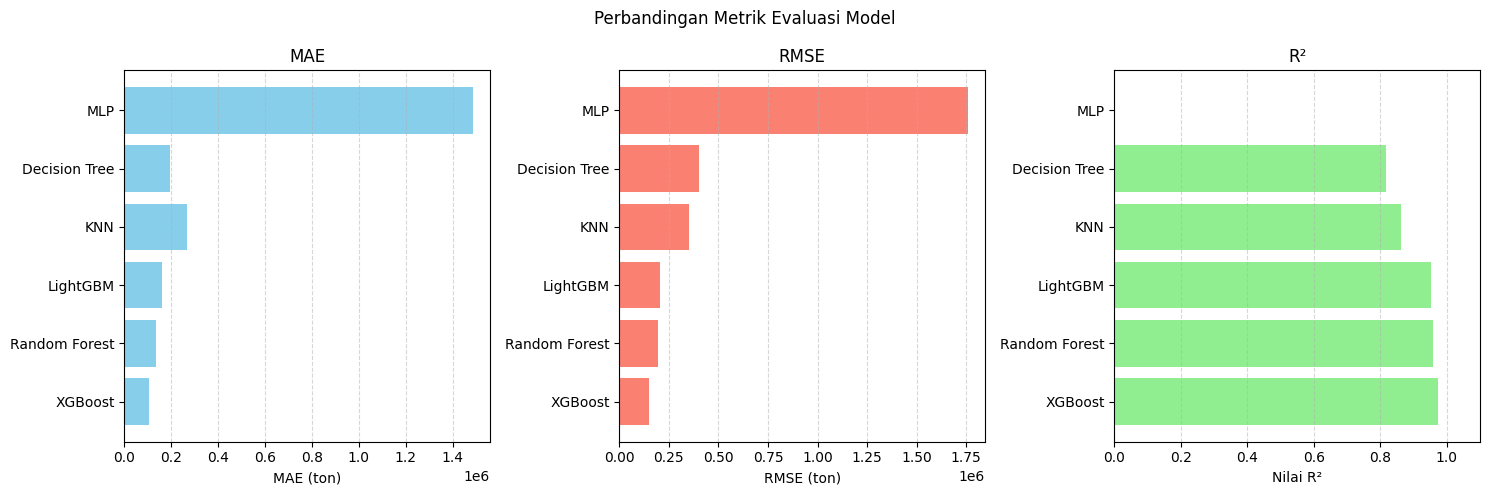

In [ ]:
# ============================================================
# 6.3 Visualisasi: Bar Chart Perbandingan Metrik Evaluasi
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# MAE
axes[0].barh(df_eval['Model'], df_eval['MAE'], color='skyblue')
axes[0].set_title('MAE')
axes[0].set_xlabel('MAE (ton)')
axes[0].grid(True, axis='x', linestyle='--', alpha=0.5)

# RMSE
axes[1].barh(df_eval['Model'], df_eval['RMSE'], color='salmon')
axes[1].set_title('RMSE')
axes[1].set_xlabel('RMSE (ton)')
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)

# R²
axes[2].barh(df_eval['Model'], df_eval['R²'], color='lightgreen')
axes[2].set_title('R²')
axes[2].set_xlabel('Nilai R²')
axes[2].set_xlim(0, 1.1)
axes[2].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Perbandingan Metrik Evaluasi Model')
plt.tight_layout()
plt.show()

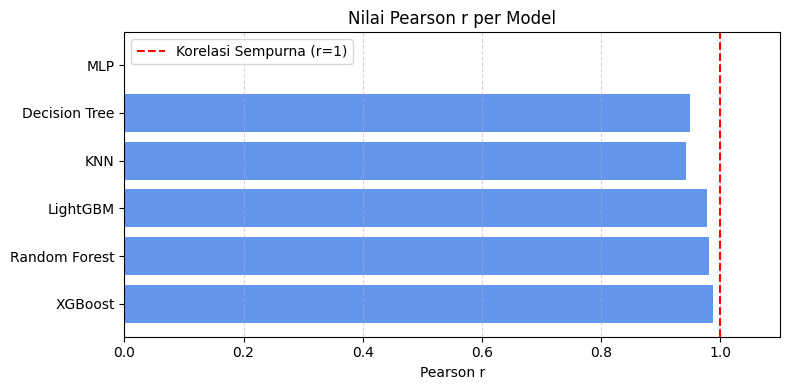

In [ ]:
# ============================================================
# 6.4 Visualisasi: Pearson Correlation per Model
# ============================================================

plt.figure(figsize=(8, 4))

plt.barh(df_eval['Model'], df_eval['Pearson r'], color='cornflowerblue')
plt.axvline(x=1.0, color='red', linestyle='--', label='Korelasi Sempurna (r=1)')

plt.title('Nilai Pearson r per Model')
plt.xlabel('Pearson r')
plt.xlim(0, 1.1)
plt.legend()
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()